In [1]:
import os
os.environ['TF_CPP_MIN_LOG_LEVEL'] = '3'

In [2]:
import pandas as pd
import numpy as np

df = pd.read_csv('./dataset.csv')

In [3]:
df

,algorithm,encrypt
0,caesar,nbynluayxsizguwvynb
1,caesar,khfruurjvbqjtnbynjan
2,caesar,vjseslakhwjkgfsw
3,caesar,qhapnaxvatbsfpbgynaq
4,caesar,thjilaoaohulvmnshtpzhukjhdkvyhnlulyhspuaolrpunz
...,...,...
34070,substitution,osbmcsiqxssgsjeooqxsesixmsicobxdcgii
34071,substitution,mfhfdgepnfmdfpsnneffg
34072,substitution,smsfdpoddmjgdidapsdpjssjgmjdcsdblaldsdddms
34073,substitution,olmqhlslii


In [4]:
df.algorithm.unique()

array(['caesar', 'affine', 'vigenere', 'rail_fence', 'substitution'],
      dtype=object)

In [5]:
df = df[
    df.algorithm.isin(['caesar', 'affine', 'vigenere', 'rail_fence'])
]

In [6]:
# Step 1 -> convert text to numbers using textVocab
from tensorflow.keras.layers import TextVectorization

vectorize_layer = TextVectorization(
    max_tokens=100,
    split="character",
    output_mode = 'int',
)

vectorize_layer.adapt(df.encrypt.to_list())

In [7]:
vectorized_strings = np.array([vectorize_layer(s).numpy() for s in df['encrypt']], dtype='object')
vectorized_strings.shape

(27260,)

In [8]:
images = np.array(
    [[vector for _ in range(len(vector))] for vector in vectorized_strings]
, dtype='object')
images.shape

(27260,)

In [9]:
import cv2

X = np.array(
    [cv2.resize(np.array(image, dtype='uint8'), dsize=(64,64)) for image in images]
)
X.shape

(27260, 64, 64)

In [10]:
X = X.reshape(-1,64,64,1)
X.shape

(27260, 64, 64, 1)

In [11]:
input_shape = X[0].shape
input_shape

(64, 64, 1)

In [12]:
y = pd.get_dummies(df[['algorithm']])

In [13]:
X.shape

(27260, 64, 64, 1)

In [14]:
y.shape

(27260, 4)

In [15]:
output_shape = y.shape[1]

In [16]:
from sklearn.model_selection import train_test_split
x_train, x_rem, y_train, y_rem = train_test_split(X, y, test_size=0.2, random_state=42)
x_val, x_test, y_val, y_test = train_test_split(x_rem, y_rem, test_size=0.2, random_state=42)

# Training

In [17]:
import tensorflow as tf
from tensorflow.keras.layers import Conv2D, \
BatchNormalization, MaxPool2D, Flatten, Dense, Dropout

model = tf.keras.models.Sequential()

model.add(tf.keras.Input(shape=input_shape))

model.add(Conv2D(64, (3,3), activation='relu'))
model.add(MaxPool2D())
model.add(BatchNormalization())

model.add(Dropout(0.1))
model.add(Conv2D(128, (3,3), activation='relu'))
model.add(MaxPool2D())
model.add(BatchNormalization())

model.add(Dropout(0.1))
model.add(Conv2D(256, (3,3), activation='relu'))
model.add(MaxPool2D())
model.add(BatchNormalization())

model.add(Flatten())

model.add(Dropout(0.1))
model.add(Dense(units=2048, activation='relu'))
model.add(BatchNormalization())

model.add(Dropout(0.1))
model.add(Dense(units=512, activation='relu'))
model.add(BatchNormalization())

model.add(Dropout(0.1))
model.add(Dense(units=128, activation='relu'))
model.add(BatchNormalization())

model.add(Dropout(0.1))
model.add(Dense(units=32, activation='relu'))
model.add(BatchNormalization())

model.add(Dense(units=output_shape, activation='softmax'))

In [18]:
model.summary()

Model: "sequential"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 conv2d (Conv2D)             (None, 62, 62, 64)        640       
                                                                 
 max_pooling2d (MaxPooling2D  (None, 31, 31, 64)       0         
 )                                                               
                                                                 
 batch_normalization (BatchN  (None, 31, 31, 64)       256       
 ormalization)                                                   
                                                                 
 dropout (Dropout)           (None, 31, 31, 64)        0         
                                                                 
 conv2d_1 (Conv2D)           (None, 29, 29, 128)       73856     
                                                                 
 max_pooling2d_1 (MaxPooling  (None, 14, 14, 128)      0

In [19]:
from tensorflow.keras.callbacks import EarlyStopping

model.compile(
    loss="categorical_crossentropy", metrics=["accuracy"]
)
callback = [
    EarlyStopping(
        monitor='val_accuracy',
        patience=10,
        restore_best_weights=True
    )
]

history = model.fit(
    x_train,
    y_train,
    epochs=10000,
    validation_data=(x_val, y_val),
    callbacks=callback,
)

Epoch 1/10000
682/682 [==============================] - 31s 34ms/step - loss: 1.0074 - accuracy: 0.4888 - val_loss: 0.9678 - val_accuracy: 0.5127
Epoch 2/10000
682/682 [==============================] - 22s 33ms/step - loss: 0.9517 - accuracy: 0.5084 - val_loss: 0.9267 - val_accuracy: 0.4916
Epoch 3/10000
682/682 [==============================] - 22s 33ms/step - loss: 0.9392 - accuracy: 0.5205 - val_loss: 0.9187 - val_accuracy: 0.5396
Epoch 4/10000
682/682 [==============================] - 22s 32ms/step - loss: 0.9271 - accuracy: 0.5281 - val_loss: 0.9254 - val_accuracy: 0.5373
Epoch 5/10000
682/682 [==============================] - 22s 32ms/step - loss: 0.9158 - accuracy: 0.5361 - val_loss: 0.9643 - val_accuracy: 0.5290
Epoch 6/10000
682/682 [==============================] - 22s 32ms/step - loss: 0.9034 - accuracy: 0.5540 - val_loss: 0.8864 - val_accuracy: 0.5639
Epoch 7/10000
682/682 [==============================] - 23s 34ms/step - loss: 0.8924 - accuracy: 0.5646 - val_loss: 0

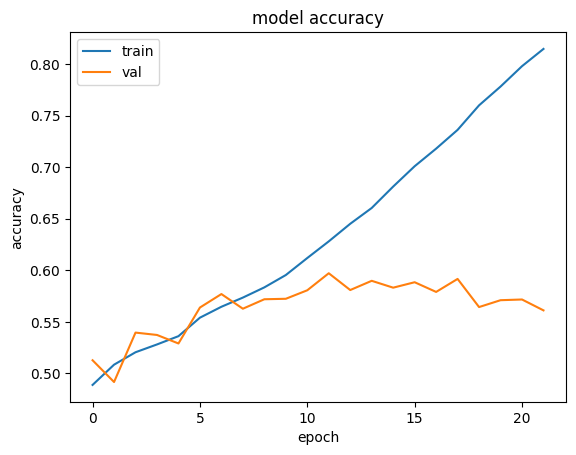

In [20]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])
plt.title('model accuracy')
plt.ylabel('accuracy')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

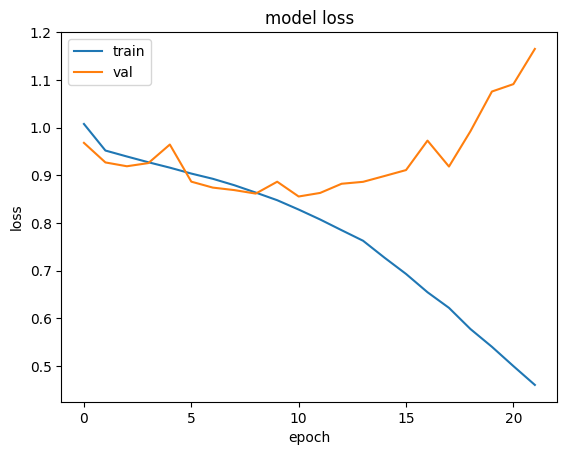

In [21]:
import matplotlib.pyplot as plt

plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])
plt.title('model loss')
plt.ylabel('loss')
plt.xlabel('epoch')
plt.legend(['train', 'val'], loc='upper left')
plt.show()

In [22]:
model.save('./model_4_class')

INFO:tensorflow:Assets written to: ./model_4_class/assets


In [23]:
test_loss, test_acc = model.evaluate(x_val, y_val)
print(f"test_loss={test_loss}, test_acc={test_acc}")

137/137 [==============================] - 2s 11ms/step - loss: 0.8628 - accuracy: 0.5971
test_loss=0.8627747893333435, test_acc=0.5971107482910156
